<center><h1>Chen_Chien-Ting_HW5</h1></center>
<br>
<br>

Name: Chien-Ting Chen
<br>
Github Username: jessica91816
<br>
USC ID: 2009118611

## 1. Decision Trees as Interpretable Models

Import packages

In [5]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import export_text
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [8]:
columns = [
    'temperature',
    'nausea',
    'lumbar-pain',
    'urine-pushing',
    'micturition-pains',
    'burning-urethra',
    'bladder-inflammation',
    'nephritis',
]
df = pd.read_csv(
    'diagnosis.data',
    sep = '\t',
    header = None,
    names = columns,
    encoding = 'utf-16',
    decimal=','
)
df.head()

,temperature,nausea,lumbar-pain,urine-pushing,micturition-pains,burning-urethra,bladder-inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


In [9]:
label = {
    'no_no': 0,
    'yes_no': 1,
    'no_yes': 2,
    'yes_yes': 3,
}

y = (df['bladder-inflammation'] + '_' + df['nephritis']).map(label)
y.value_counts().sort_index()
X = df.iloc[:,:6].copy()

for column in X.columns[1:]:
    X[column] = X[column].map({'no':0, 'yes':1})
X.head()

,temperature,nausea,lumbar-pain,urine-pushing,micturition-pains,burning-urethra
0,35.5,0,1,0,0,0
1,35.9,0,0,1,1,1
2,35.9,0,1,0,0,0
3,36.0,0,0,1,1,1
4,36.0,0,1,0,0,0


### (b) Build a decision tree

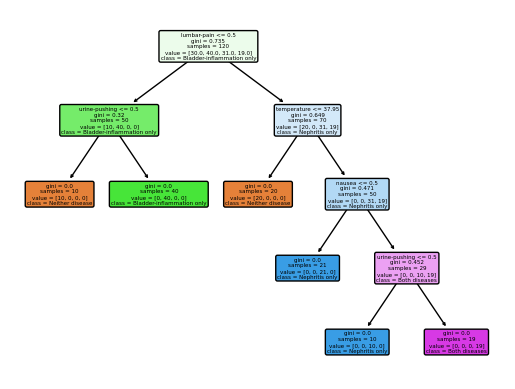

In [11]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X,y)
plot_tree(
    tree,
    feature_names=X.columns.tolist(),
    class_names=[
        'Neither disease',
        'Bladder-inflammation only',
        'Nephritis only',
        'Both diseases'
    ],
    filled=True,
    rounded=True  
)
plt.show()

In [12]:
print(export_text(
    tree,
    feature_names=X.columns.tolist(),
    decimals=2
))

|--- lumbar-pain <= 0.50
|   |--- urine-pushing <= 0.50
|   |   |--- class: 0
|   |--- urine-pushing >  0.50
|   |   |--- class: 1
|--- lumbar-pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: 0
|   |--- temperature >  37.95
|   |   |--- nausea <= 0.50
|   |   |   |--- class: 2
|   |   |--- nausea >  0.50
|   |   |   |--- urine-pushing <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- urine-pushing >  0.50
|   |   |   |   |--- class: 3



### (c) Convert the decision rules

1. If lumbar-pain <= 0.50 and urine-pushing <= 0.50,
   then predict Neither disease.
2. If lumbar-pain <= 0.50 and urine-pushing > 0.50,
   then predict Bladder-inflammation only.
3. If lumbar-pain > 0.50 and temperature <= 37.95,
   then predict Neither disease.
4. If lumbar-pain > 0.50 and temperature > 37.95 and nausea <= 0.50,
   then predict Nephritis only.
5. If lumbar-pain > 0.50 and temperature > 37.95 and nausea > 0.50 and urine-pushing <= 0.50,
   then predict Nephritis only.
6. If lumbar-pain > 0.50 and temperature > 37.95 and nausea > 0.50 and urine-pushing > 0.50,
   then predict Both diseases.

### 1.4. (d) Cost-complexity pruning

In [16]:
path = tree.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas
print(alphas)

[0.         0.09816667 0.13333333 0.182      0.22291667]


In [17]:
results = []

for alpha in alphas:
    pruned_tree = DecisionTreeClassifier(
        random_state = 42,
        ccp_alpha = alpha
    )
    pruned_tree.fit(X,y)
    results.append({
        'alpha': alpha,
        'leaves':pruned_tree.get_n_leaves(),
        'depth':pruned_tree.get_depth(),
        'training_accuracy': pruned_tree.score(X,y)
    })
pruning_results = pd.DataFrame(results)
pruning_results

,alpha,leaves,depth,training_accuracy
0,0.000000,6,4,1.000000
1,0.098167,4,2,0.841667
2,0.133333,3,2,0.758333
3,0.182000,2,1,0.591667
4,0.222917,1,0,0.333333


I chose alpha = 0.098167 to balance interpretability and accuracy. Pruning reduces the number of rules from 6 to 4 and the tree depth from 4 to 2, while training accuracy decreases from 100% to 84.17%. The smaller tree is easier to interpret.

In [19]:
best_alpha = alphas[1]

pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)
pruned_tree.fit(X,y)
print(export_text(
    pruned_tree,
    feature_names=X.columns.tolist(),
    decimals=2
))

|--- lumbar-pain <= 0.50
|   |--- urine-pushing <= 0.50
|   |   |--- class: 0
|   |--- urine-pushing >  0.50
|   |   |--- class: 1
|--- lumbar-pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: 0
|   |--- temperature >  37.95
|   |   |--- class: 2



1. If lumbar-pain <= 0.50 and urine-pushing <= 0.50, then predict Neither disease.
2. If lumbar-pain <= 0.50 and urine-pushing > 0.50, then predict Bladder-inflammation only.
3. If lumbar-pain > 0.50 and temperature <= 37.95, then predict Neither disease.
4. If lumbar-pain > 0.50 and temperature >  37.95, then predict Nephritis only.

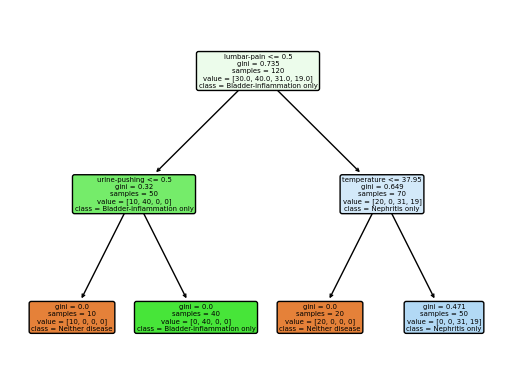

In [21]:
plot_tree(
    pruned_tree,
    feature_names=X.columns.tolist(),
    class_names=[
        'Neither disease',
        'Bladder-inflammation only',
        'Nephritis only',
        'Both diseases'
    ],
    filled=True,
    rounded=True
)
plt.show()

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [24]:
columns_2=[]
with open('communities.names') as file:
    for line in file:
        if line.lower().startswith('@attribute'):
            columns_2.append(line.split()[1])
df_2 = pd.read_csv(
    'communities.data',
    header = None,
    names=columns_2,
    na_values='?'
)
df_2.head()

train_df = df_2.iloc[:1495].copy()
test_df = df_2.iloc[1495:].copy()
print(train_df.shape)
print(test_df.shape)

(1495, 128)
(499, 128)


### (b) Missing values

In [26]:
non_predictive=[
    'state',
    'county',
    'community',
    'communityname',
    'fold'
]
target = 'ViolentCrimesPerPop'

X_train = train_df.drop(columns=non_predictive+[target])
X_test = test_df.drop(columns=non_predictive+[target])
y_train = train_df[target].copy()
y_test = test_df[target].copy()

print(X_train.shape)
print(X_test.shape)
missing = X_train.isna().sum()
missing[missing>0]
train_medians = X_train.median()
X_train_imputed = X_train.fillna(train_medians)
X_test_imputed = X_test.fillna(train_medians)

print(X_train_imputed.isna().sum().sum())
print(X_test_imputed.isna().sum().sum())

(1495, 122)
(499, 122)
0
0


### (c) Plot a correlation matrix

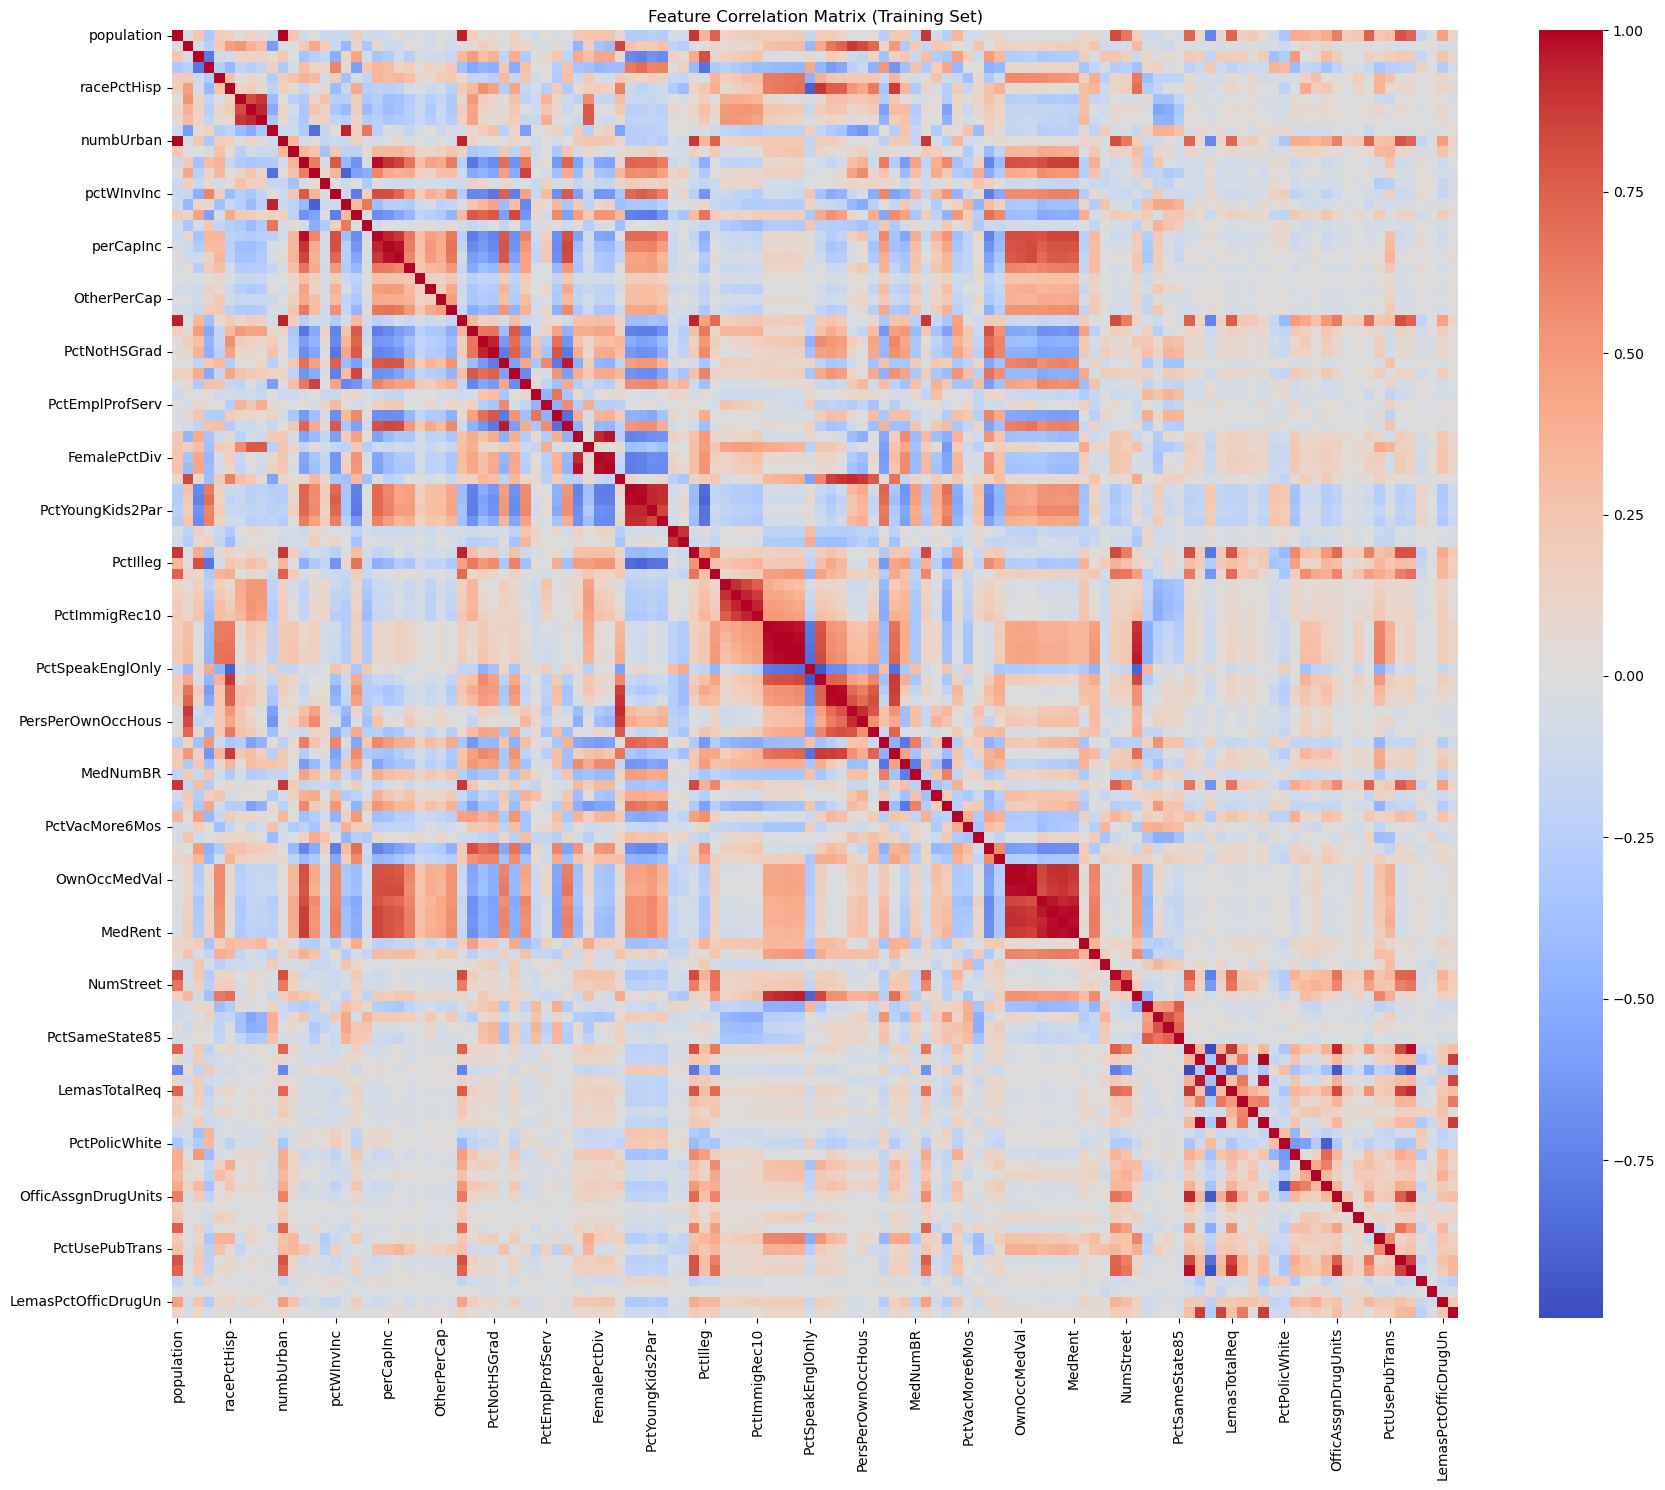

In [28]:
corr_matrix = X_train_imputed.corr()
plt.figure(figsize=(18,15))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    xticklabels=5,
    yticklabels=5
)
plt.title('Feature Correlation Matrix (Training Set)')
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [30]:
cv = X_train_imputed.std(ddof=1) / X_train_imputed.mean()
cv_sorted = cv.sort_values(ascending=False)
cv_sorted.head(15)

PctPolicAsian          5.527059
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
LemasSwornFT           2.248042
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
PolicOperBudg          1.645508
LandArea               1.645408
racePctHisp            1.612091
PctNotSpeakEnglWell    1.456618
dtype: float64

### (e) Scatter plots and box plots for highest CV features

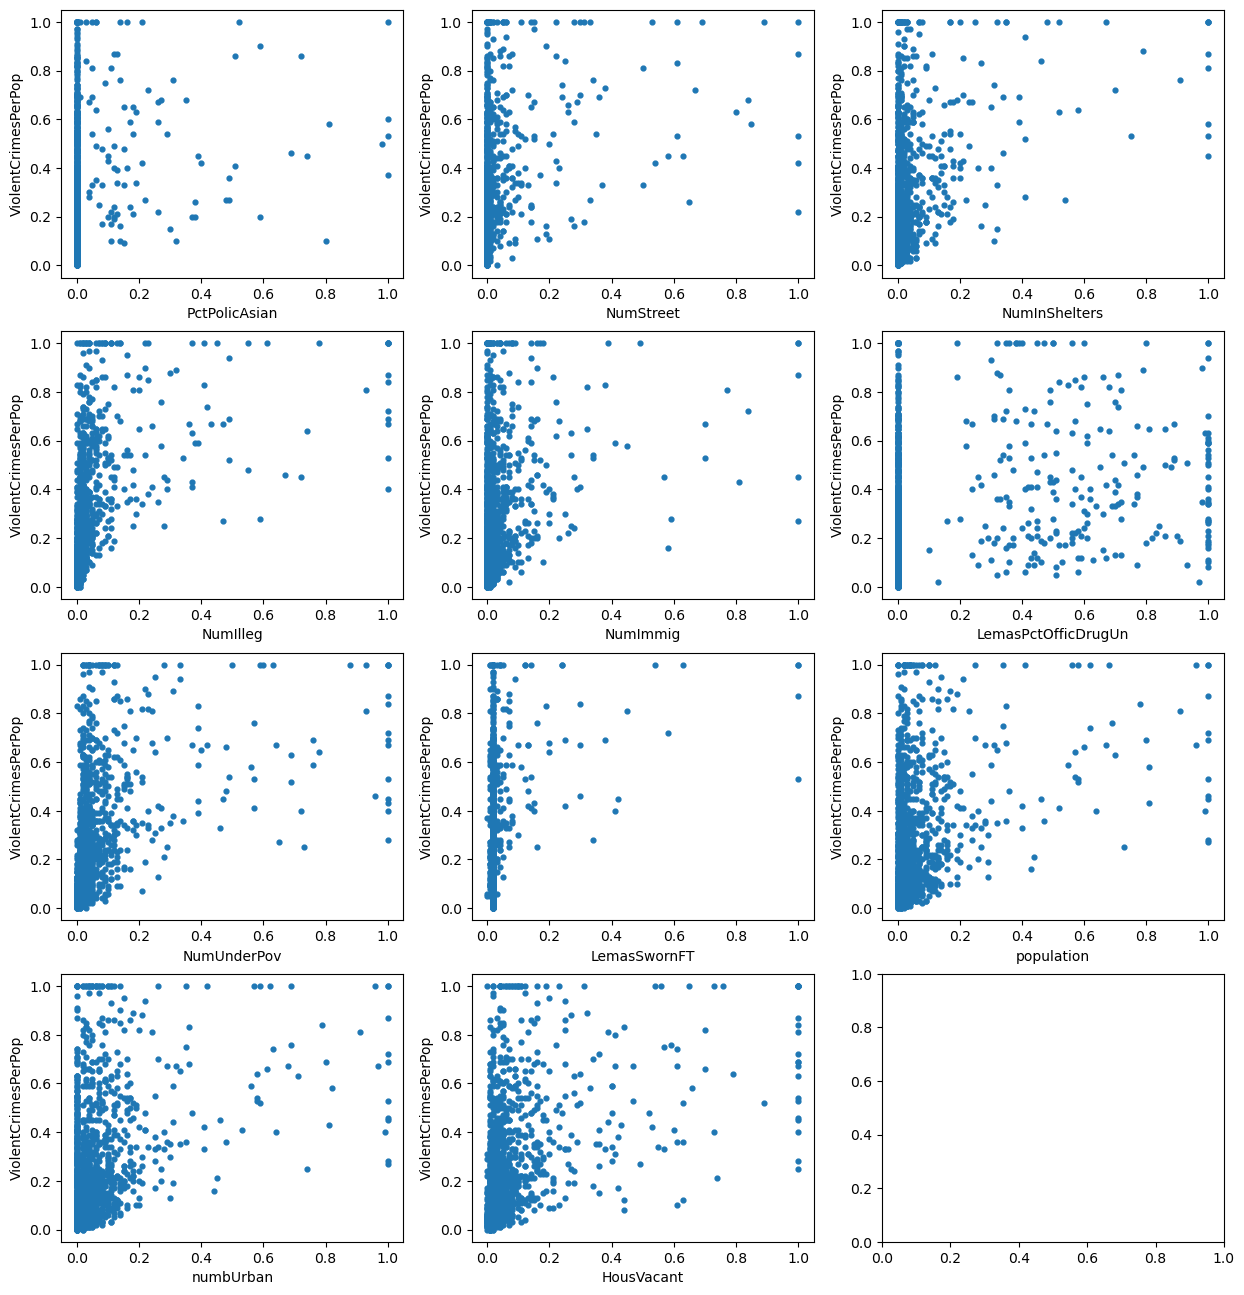

In [32]:
highest_features = cv_sorted.head(11).index

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, feature in zip(axes.flat, highest_features):
    ax.scatter(
        X_train_imputed[feature],
        y_train,
        s=12
    )
    ax.set_xlabel(feature)
    ax.set_ylabel('ViolentCrimesPerPop')
#axes.flat[-1].axis('off')
plt.show()

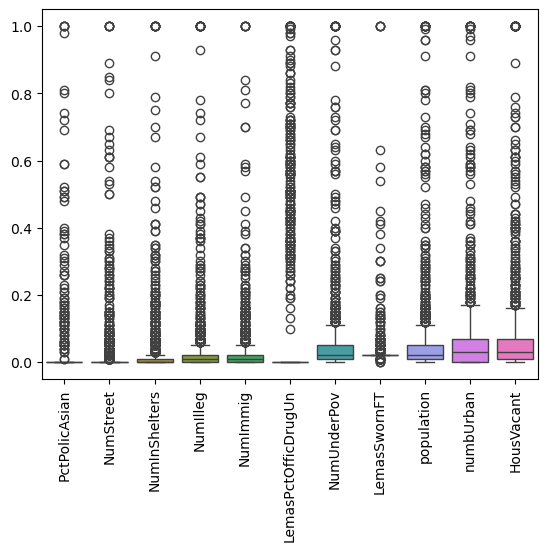

In [33]:
sns.boxplot(data=X_train_imputed[highest_features])
plt.xticks(rotation=90)
plt.show()

Scatter plots allow us to observe the trends and relationships between the features and target. However, without statistical tests or regression analysis, we are not able to draw conclusions about significance.

### (f) Fit a linear model

In [36]:
lr = LinearRegression()
lr.fit(X_train_imputed, y_train)
y_pred = lr.predict(X_test_imputed)
mse = mean_squared_error(y_test, y_pred)
print(f'Original test MSE: {mse}')

# 'LemasSwFTPerPop' and 'PolicPerPop' are the same in training set.
# So, remove the duplicate 'PolicPerPop' and train again.
X_train_lr = X_train_imputed.drop(columns=['PolicPerPop'])
X_test_lr = X_test_imputed.drop(columns=['PolicPerPop'])
lr.fit(X_train_lr, y_train)
y_pred = lr.predict(X_test_lr)
mse_modify = mean_squared_error(y_test, y_pred)
print(f'Test MSE after removing duplicate: {mse_modify}')

Original test MSE: 1.8902932666537196e+16
Test MSE after removing duplicate: 0.01796607862869667


### (g) Fit a ridge regression model

In [38]:
ridge_pip = Pipeline([('imputer', SimpleImputer(strategy='median')), 
                      ('ridge', Ridge())])
ridge_alphas = np.logspace(-4, 4, 100)
param_grid = {'ridge__alpha':ridge_alphas}
ridge_search = GridSearchCV(estimator = ridge_pip, param_grid=param_grid,
                           cv=5, scoring='neg_mean_squared_error')
ridge_search.fit(X_train, y_train)
y_pred = ridge_search.predict(X_test)
ridge_mse = mean_squared_error(y_test, y_pred)
print(ridge_mse)
print(ridge_search.best_params_)

0.01751624930256488
{'ridge__alpha': 2.310129700083163}


### (h) Fit a LASSO model

In [40]:
lasso_pip = Pipeline([('imputer', SimpleImputer(strategy='median')), 
                      ('lasso', Lasso(max_iter=100000))])
lasso_alphas = np.logspace(-5, 0, 100)
param_grid = {'lasso__alpha':lasso_alphas}
lasso_search = GridSearchCV(estimator = lasso_pip, param_grid=param_grid,
                           cv=5, scoring='neg_mean_squared_error')
lasso_search.fit(X_train, y_train)
y_pred = lasso_search.predict(X_test)
lasso_mse = mean_squared_error(y_test, y_pred)
print(lasso_mse)
print(lasso_search.best_params_)
best_lasso = lasso_search.best_estimator_.named_steps['lasso']
lasso_coef = pd.Series(best_lasso.coef_, index=X_train.columns)
print(lasso_coef[lasso_coef != 0].to_string())

lasso_std_pip = Pipeline([('imputer', SimpleImputer(strategy='median')), 
                          ('scaler', StandardScaler()),
                          ('lasso', Lasso(max_iter=100000)),])
lasso_std_search = GridSearchCV(estimator = lasso_std_pip, param_grid=param_grid,
                           cv=5, scoring='neg_mean_squared_error')
lasso_std_search.fit(X_train, y_train)
y_pred_std = lasso_std_search.predict(X_test)
lasso_std_mse = mean_squared_error(y_test, y_pred_std)
print(lasso_std_mse)
print(lasso_std_search.best_params_)
best_std_lasso = lasso_std_search.best_estimator_.named_steps['lasso']
lasso_std_coef = pd.Series(best_std_lasso.coef_, index=X_train.columns)
print(lasso_std_coef[lasso_std_coef != 0].to_string())

0.0176104875162623
{'lasso__alpha': 0.0001291549665014884}
racepctblack             0.266980
racePctAsian            -0.013939
agePct12t21              0.055295
agePct12t29             -0.240500
pctUrban                 0.040470
pctWWage                -0.075514
pctWFarmSelf             0.024797
pctWInvInc              -0.095619
pctWSocSec               0.045548
pctWPubAsst              0.037751
pctWRetire              -0.106236
whitePerCap             -0.053025
blackPerCap             -0.021067
indianPerCap            -0.030263
AsianPerCap              0.028319
OtherPerCap              0.022615
HispPerCap               0.021455
PctPopUnderPov          -0.136162
PctLess9thGrade         -0.016032
PctEmploy                0.125368
PctEmplManu             -0.013747
PctOccupManu             0.009271
MalePctDivorce           0.110946
MalePctNevMarr           0.119485
FemalePctDiv            -0.068910
PctKids2Par             -0.198095
PctYoungKids2Par        -0.040519
PctTeen2Par            

The MSE before standardization is slightly lower than the one after standardization. So, standardization did not improve test MSE in this experiment.

### (i) Fit a PCR model

In [43]:
pcr_pip = Pipeline([('imputer', SimpleImputer(strategy='median')), 
                   ('scaler', StandardScaler()),
                   ('pca', PCA(svd_solver='full')),
                   ('regression', LinearRegression())])
pcr_param_grid = {'pca__n_components':range(1, X_train.shape[1] + 1)}
pcr_search = GridSearchCV(estimator = pcr_pip, param_grid=pcr_param_grid,
                           cv=5, scoring='neg_mean_squared_error')
pcr_search.fit(X_train, y_train)
y_pred_pcr = pcr_search.predict(X_test)
pcr_mse = mean_squared_error(y_test, y_pred_pcr)
print(pcr_mse)
print(pcr_search.best_params_)

0.018296345367709826
{'pca__n_components': 95}


### (j) Fit a boosting tree

In [45]:
xgb_pip = Pipeline([('imputer', SimpleImputer(strategy='median')), 
                   ('xgb', XGBRegressor(objective='reg:squarederror',
                   random_state=42))])
xgb_alphas=[0, 0.01, 0.1, 1, 10, 100]
xgb_param_grid = {'xgb__reg_alpha':xgb_alphas}
xgb_search = GridSearchCV(estimator = xgb_pip, param_grid=xgb_param_grid,
                           cv=5, scoring='neg_mean_squared_error')
xgb_search.fit(X_train, y_train)
y_pred_xgb = xgb_search.predict(X_test)
xgb_mse = mean_squared_error(y_test, y_pred_xgb)
print(xgb_mse)
print(xgb_search.best_params_)

0.017927099271879313
{'xgb__reg_alpha': 1}
